# Document Parsing with Mistral OCR 4

> **Sponsored by Mistral AI.** The failure documented here is reproducible against this
> repository, every cell runs, and the conclusions are the author's own.

## Overview

Every technique in this repository begins by turning a document into text. That first step is
treated as solved: a PDF goes into a loader, text comes out, and the interesting work starts
afterwards. This notebook examines the step itself.

Using a two-column academic PDF containing a results table, we run the repository's own
`encode_pdf()` helper, show that the answer to a specific question has been destroyed before
indexing, then swap the parser for [Mistral OCR 4](https://mistral.ai/news/ocr-4/) and repeat
the identical pipeline: same splitter, same embeddings, same vector store, same retriever, same
prompt, same model. OCR 4 restores the table, and the character splitter then cuts it off from
its caption, so the answer is still lost. The third pipeline chunks on the block types OCR 4
returns and keeps the table and its caption together. Finally the repository's own reranker runs
over all three pipelines: on the PyPDF chunks it makes the model confidently wrong, and on the
block-aware chunks it gets the right answer.

## Motivation

Retrieval quality is capped by ingestion quality, and ingestion is the one part of a RAG
pipeline with no knobs to tune, so it rarely gets inspected.

This repository has 41 notebooks in `all_rag_techniques/`. Thirty-one of them touch a PDF.
Sixteen ingest one through a PyPDF path, eleven of those through the shared `encode_pdf()`
helper in `helper_functions.py`. Not one of the 41 prints what the parser produced.

When a PDF carries a table, or has no text layer at all, a plain text extractor returns the
characters and discards the structure that gave them meaning. A number survives; the column
header that told you what it measured does not. No amount of reranking, query rewriting or
chunk-size tuning recovers it, because the loss happened before the chunker ever ran.

## Key Components

1. A baseline built from the repository's own `encode_pdf()` helper, imported rather than
   rewritten, so the comparison is against what these notebooks actually use
2. A diagnostic cell that prints raw chunk text instead of summarising it
3. Mistral OCR 4 as a drop-in replacement for the parsing step
4. Pre-computed OCR output committed alongside the notebook, so every cell runs without a
   Mistral account
5. A block-aware chunker that uses OCR 4's structural labels to keep each table whole and
   together with its caption, which a character-based splitter cannot guarantee at any setting
6. The repository's own LLM reranker, applied identically to all three pipelines
7. A quantitative comparison of all three pipelines

## Method Details

### The baseline

`encode_pdf()` loads a PDF with `PyPDFLoader`, splits it with `RecursiveCharacterTextSplitter`
at 1000 characters with 200 overlap, replaces tabs with spaces, embeds with OpenAI embeddings
and indexes into FAISS. PyPDF emits a character stream. On the paper used here it gets the
reading order of the two columns right, and still flattens the results table into rows of
unlabelled numbers whose column headers are on a separate line.

### The replacement

Mistral OCR 4 returns a structured representation of each page rather than a character stream:
markdown with reading order resolved and tables preserved as markdown tables, plus, for every
block, a bounding box, a block type and a confidence score.

### The third pipeline

Because OCR 4 labels block types, chunk boundaries can follow document structure instead of
character counts. Tables become atomic, so a table is never split mid-row, and each table
travels with its caption, the block that says what its numbers measure.

### The reranker

The LLM reranker from this repository's reranking notebook scores ten candidates for relevance
and keeps the best three. It runs unchanged over all three pipelines, so any difference in the
final answer comes from the chunks it was given.

## Benefits

- The failure is demonstrated rather than asserted, by printing the indexed text
- The comparison is controlled: each pipeline changes one thing, so each result is attributable to that change
- Readers without a Mistral API key still execute every cell
- The structural chunker is a technique that transfers to any structure-aware parser

## Conclusion

Most RAG pipelines that appear to need a better retriever need better ingestion: a parser that
keeps the structure, and a chunker that does not throw it away again. The diagnostic costs one
cell: print your chunks and read them.

### Visual Representation

<div style="text-align: center;">
<img src="../images/document_parsing_with_mistral_ocr.svg" alt="Document parsing with Mistral OCR 4" style="width:100%; height:auto;">
</div>

# Package Installation and Imports

The cell below installs all necessary packages required to run this notebook.

In [ ]:
# Install required packages
!pip install pypdf==5.6.0
!pip install PyMuPDF==1.26.1
!pip install python-dotenv==1.1.0
!pip install langchain-community==0.3.25
!pip install langchain_openai==0.3.23
!pip install faiss-cpu==1.11.0
!pip install mistralai==3.2.0

Clone the repository so the notebook can import the shared helpers from `helper_functions.py`.

In [ ]:
# Clone the repository to access helper functions and evaluation modules
!git clone https://github.com/NirDiamant/RAG_TECHNIQUES.git
import sys
sys.path.append('RAG_TECHNIQUES')

# If you need to run with the latest data
# !cp -r RAG_TECHNIQUES/data .

Import the libraries, read the API keys from the environment, and decide whether the OCR cells run live or from the cached output.

In [3]:
import os
import sys
import json
import pathlib
from dotenv import load_dotenv

# Original path append replaced for Colab compatibility
from helper_functions import encode_pdf, replace_t_with_space

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate

# Load environment variables from a .env file
load_dotenv()

# OpenAI powers the embeddings and the answer model, exactly as in the other notebooks here.
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

# Mistral is OPTIONAL. Every OCR call below has a cached counterpart committed with this
# notebook, so the notebook runs end to end without a Mistral account. Set the key only to
# re-run the OCR yourself or to point it at your own document.
MISTRAL_API_KEY = os.getenv('MISTRAL_API_KEY')
USE_CACHED = MISTRAL_API_KEY is None

print("Running from cached OCR output." if USE_CACHED else "MISTRAL_API_KEY found, OCR will run live.")

MISTRAL_API_KEY found, OCR will run live.


### Download the sample documents

Three openly licensed documents. The two-column paper carries the main demonstration; the other
two appear in the final section. They are openly licensed because this notebook redistributes
their OCR output so that readers without an API key can run every cell.

In [ ]:
# Download required data files
import os
os.makedirs('data', exist_ok=True)
os.makedirs('cached_ocr', exist_ok=True)

# Two-column paper with a results table. Karpukhin et al., "Dense Passage Retrieval for
# Open-Domain Question Answering", EMNLP 2020. ACL Anthology, CC BY 4.0.
!wget -q -O data/dpr_emnlp2020.pdf https://raw.githubusercontent.com/NirDiamant/RAG_TECHNIQUES/main/data/dpr_emnlp2020.pdf

# A table that continues across a page break. Economic Report of the President 2025,
# Table B-1, three pages. A US Government work, public domain.
!wget -q -O data/erp_table_b1_extract.pdf https://raw.githubusercontent.com/NirDiamant/RAG_TECHNIQUES/main/data/erp_table_b1_extract.pdf

# Pre-computed OCR 4 output for all three documents, so every cell runs without a Mistral key.
for name in ["two_column_paper.json", "scanned_page.json", "erp_table_b1.json"]:
    !wget -q -O cached_ocr/{name} https://raw.githubusercontent.com/NirDiamant/RAG_TECHNIQUES/main/data/mistral_ocr_cache/{name}

PAPER_PDF  = "data/dpr_emnlp2020.pdf"
REPORT_PDF = "data/erp_table_b1_extract.pdf"

TABLE_PAGE   = 4          # the page holding Table 2
TABLE_ANCHOR = "Top-20"   # first header cell of that table
QUESTION     = ("What Top-20 retrieval accuracy did DPR achieve on SQuAD "
                "when it was trained on a single dataset?")
TRUTH        = "63.2"     # Table 2, Single/DPR row, Top-20 block, SQuAD column

### Look at the page before anything parses it

Read the table with your own eyes first. Two columns of body text, a header row, units in the
column headers, a caption underneath. Everything that follows is about how much of that
structure survives the trip into a vector store.

13 pages
generated data/scanned_page.pdf -> text characters PyPDF can find: 0


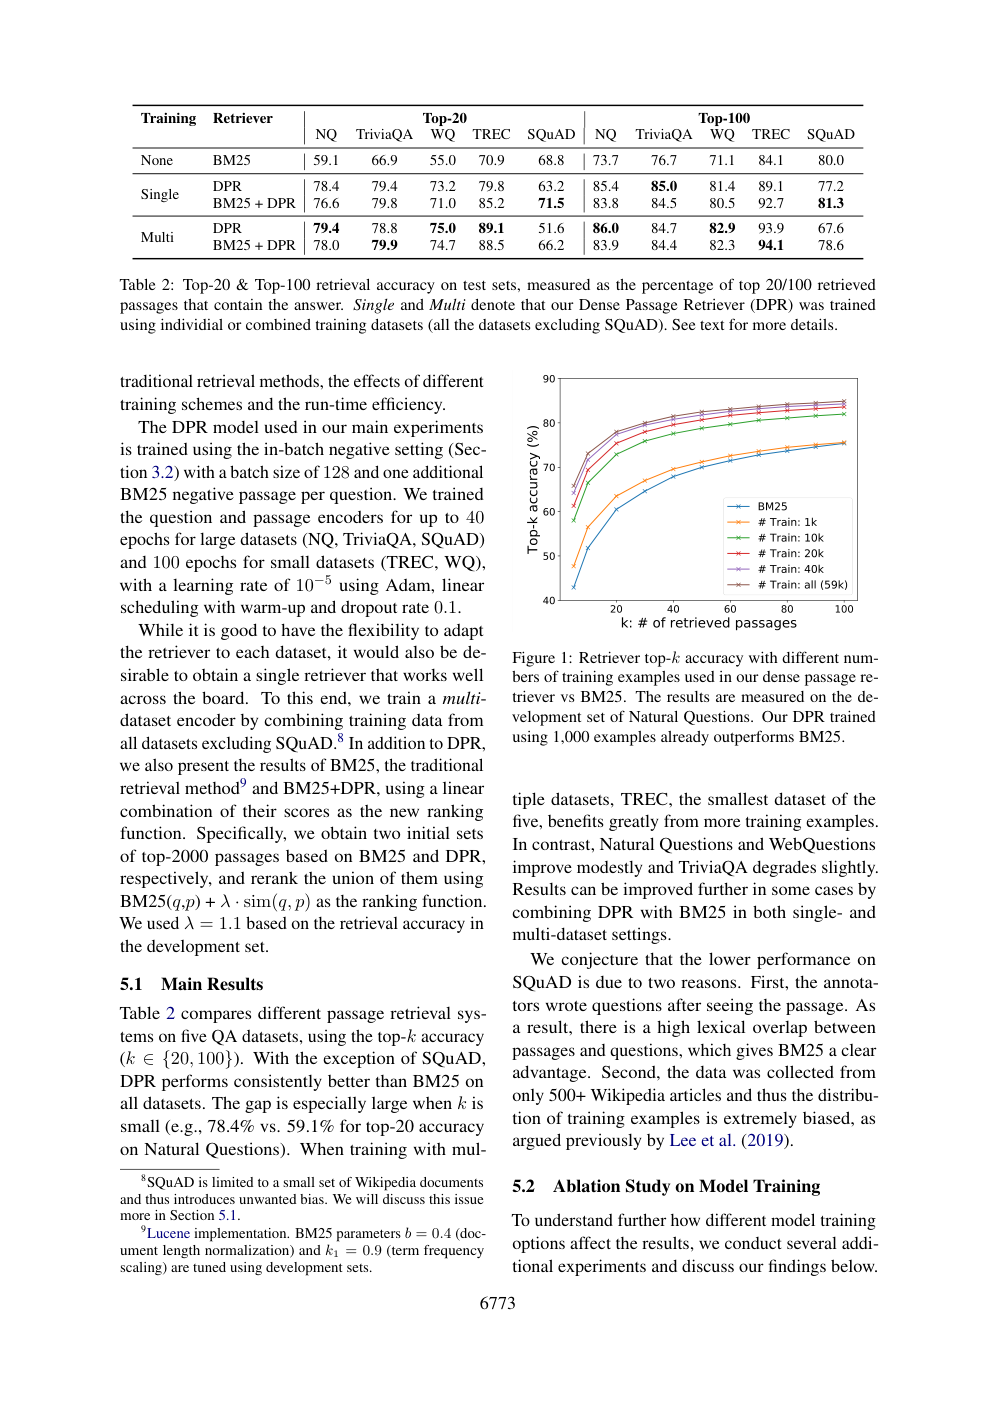

In [5]:
import fitz
from IPython.display import Image, display

doc = fitz.open(PAPER_PDF)
print(f"{doc.page_count} pages")

# The third document, a page with no text layer, is produced here rather than shipped.
# Rasterising a page of the public domain report gives a genuine image-only PDF, which is
# what a scan is, with no extra file to redistribute and nothing hidden from the reader.
SCANNED_PDF = "data/scanned_page.pdf"
_src = fitz.open(REPORT_PDF)
_pix = _src[1].get_pixmap(dpi=120)
_scan = fitz.open()
_pg = _scan.new_page(width=_src[1].rect.width, height=_src[1].rect.height)
_pg.insert_image(_pg.rect, pixmap=_pix)
_scan.save(SCANNED_PDF)
print("generated", SCANNED_PDF, "-> text characters PyPDF can find:",
      sum(len(pg.get_text().strip()) for pg in fitz.open(SCANNED_PDF)))

doc[TABLE_PAGE].get_pixmap(dpi=120).save("page.png")
display(Image("page.png"))

## Part 1. The repository's own pipeline

`encode_pdf()` is imported from `helper_functions.py` above, not reimplemented here. It is the
helper eleven notebooks in this repository call to turn a PDF into a vector store, so this is a
measurement of the real default rather than a strawman.

In [6]:
baseline_store = encode_pdf(PAPER_PDF, chunk_size=1000, chunk_overlap=200)
print(f"{baseline_store.index.ntotal} chunks indexed")

74 chunks indexed


### Print what actually got indexed

This is the diagnostic the repository never runs. Not a description of the problem, the actual
characters that went into the index.

In [7]:
pages = PyPDFLoader(PAPER_PDF).load()
raw   = pages[TABLE_PAGE].page_content

start = raw.find(TABLE_ANCHOR)
print(raw[max(0, start - 120) : start + 900])

6773
Training Retriever Top-20 Top-100
NQ TriviaQA WQ TREC SQuAD NQ TriviaQA WQ TREC SQuAD
None BM25 59.1 66.9 55.0 70.9 68.8 73.7 76.7 71.1 84.1 80.0
Single DPR 78.4 79.4 73.2 79.8 63.2 85.4 85.0 81.4 89.1 77.2
BM25 + DPR 76.6 79.8 71.0 85.2 71.5 83.8 84.5 80.5 92.7 81.3
Multi DPR 79.4 78.8 75.0 89.1 51.6 86.0 84.7 82.9 93.9 67.6
BM25 + DPR 78.0 79.9 74.7 88.5 66.2 83.9 84.4 82.3 94.1 78.6
Table 2: Top-20 & Top-100 retrieval accuracy on test sets, measured as the percentage of top 20/100 retrieved
passages that contain the answer. Single and Multi denote that our Dense Passage Retriever (DPR) was trained
using individial or combined training datasets (all the datasets excluding SQuAD). See text for more details.
traditional retrieval methods, the effects of different
training schemes and the run-time efﬁciency.
The DPR model used in our main experiments
is trained using the in-batch negative setting (Sec-
tion


### Three failures, visible in that output

Notice first what did **not** go wrong. PyPDF got the reading order right: the two columns of
body text below the table come out in the order you would read them. This is not a broken
extractor, and that is the point. The table is destroyed anyway.

**The header hierarchy is gone.** In the PDF, `Top-20` and `Top-100` are one header row, each
spanning five dataset columns underneath. In the text they are two words at the end of one
line, followed by ten dataset names on the next. Nothing records that the first `NQ TriviaQA WQ
TREC SQuAD` belongs to Top-20 and the second to Top-100.

**The row labels are gone too.** `Single` and `Multi` each span two rows in the PDF. In the text
only the first row of each group keeps its label, so the line beginning `BM25 + DPR 76.6` no
longer says whether it is the single-dataset or the multi-dataset variant.

**No value carries its column.** Every data row is ten bare numbers. To know that `63.2` is the
Top-20 accuracy on SQuAD you have to count to the fifth position and map it against a header two
lines above. Character-based chunking does not preserve that relationship and an embedding does
not encode it.

The numbers all survived. Every one of them lost its meaning.

In [8]:
retriever = baseline_store.as_retriever(search_kwargs={"k": 5})
hits = retriever.invoke(QUESTION)

for i, h in enumerate(hits, 1):
    print(f"[{i}] page {h.metadata.get('page')}  contains {TRUTH!r}: {TRUTH in h.page_content}")

[1] page 4  contains '63.2': True
[2] page 7  contains '63.2': False
[3] page 7  contains '63.2': False
[4] page 7  contains '63.2': False
[5] page 4  contains '63.2': False


### Answer the question from those chunks


In [9]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
prompt = ChatPromptTemplate.from_template(
    "Answer using only the context. If the context does not contain the answer, say so.\n\n"
    "Context:\n{context}\n\nQuestion: {question}"
)
chain = prompt | llm

def answer(hits):
    context = "\n\n".join(h.page_content for h in hits)
    return chain.invoke({"context": context, "question": QUESTION}).content

baseline_answer = answer(hits)
print(baseline_answer)

The context does not contain the answer.


### Why no retriever setting fixes this

Look at what just happened, because it is the opposite of what people assume.

**Retrieval succeeded.** The chunk containing `63.2` came back at rank 1. The chunk also
contains the caption, which says in plain English that the table reports Top-20 and Top-100
retrieval accuracy. The model was handed the right page, the right table and an explanation of
what the table is.

**It still could not answer**, and it was right not to. The text it received does not say which
of those ten numbers is the Top-20 SQuAD value. A model that guessed would have produced a
confident wrong number, which is worse.

So the usual levers do nothing here:

- **Raising `k`** retrieves more chunks. The chunk was already first.
- **A reranker** reorders chunks. The ranking was already correct. (Part 3 runs one anyway. It makes things worse.)
- **Hybrid search** runs BM25 over the same damaged text.
- **Smaller chunks** cut the same characters into smaller pieces, and the header association was
  destroyed before the splitter ever ran.

Every one of those is a retrieval fix for an ingestion problem. The loss happened inside
`loader.load()`, on the second line of `encode_pdf()`, before anything in this repository got a
chance to be clever.

## Part 2. Mistral OCR 4 as the parsing step

Mistral OCR 4 is a document understanding model rather than a text extractor. A text extractor
returns characters; OCR 4 returns a structured representation of the page: markdown with reading
order resolved and tables preserved as tables, plus a bounding box, a block type and a
confidence score for every block.

Below, the markdown restores the table's columns and rows. Then the same character splitter gets
its turn, and Part 3 uses the block types to deal with what it does.

In [10]:
from mistralai.client import Mistral

def run_ocr(path):
    # Upload a PDF and return the OCR response as a plain dict.
    client = Mistral(api_key=MISTRAL_API_KEY)
    uploaded = client.files.upload(
        file={"file_name": os.path.basename(path), "content": open(path, "rb")},
        purpose="ocr",
    )
    signed = client.files.get_signed_url(file_id=uploaded.id)
    response = client.ocr.process(
        model="mistral-ocr-latest",
        document={"type": "document_url", "document_url": signed.url},
        confidence_scores_granularity="block",   # confidence is off by default
    )
    return response.model_dump()

def ocr_or_cached(path, cache_name):
    # Run OCR, or load the committed result so the notebook works without a key.
    cached = pathlib.Path("cached_ocr") / cache_name
    if USE_CACHED:
        return json.loads(cached.read_text())
    result = run_ocr(path)
    cached.write_text(json.dumps(result, indent=2))
    return result

ocr = ocr_or_cached(PAPER_PDF, "two_column_paper.json")
print(f"{len(ocr['pages'])} pages returned")

13 pages returned


### The same page, as OCR 4 returns it

Compare this against the raw text printed earlier. The table is a markdown table, headers sit
above their columns, rows are rows, and the body text is in reading order.

In [11]:
from IPython.display import Markdown

page_md = ocr["pages"][TABLE_PAGE]["markdown"]
start   = page_md.find(TABLE_ANCHOR)
display(Markdown(page_md[max(0, start - 120) : start + 900]))

|  Training | Retriever | Top-20 |   |   |   |   | Top-100  |   |   |   |   |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
|   |   |  NQ | TriviaQA | WQ | TREC | SQuAD | NQ | TriviaQA | WQ | TREC | SQuAD  |
|  None | BM25 | 59.1 | 66.9 | 55.0 | 70.9 | 68.8 | 73.7 | 76.7 | 71.1 | 84.1 | 80.0  |
|  Single | DPR | 78.4 | 79.4 | 73.2 | 79.8 | 63.2 | 85.4 | 85.0 | 81.4 | 89.1 | 77.2  |
|   |  BM25 + DPR | 76.6 | 79.8 | 71.0 | 85.2 | 71.5 | 83.8 | 84.5 | 80.5 | 92.7 | 81.3  |
|  Multi | DPR | 79.4 | 78.8 | 75.0 | 89.1 | 51.6 | 86.0 | 84.7 | 82.9 | 93.9 | 67.6  |
|   |  BM25 + DPR | 78.0 | 79.9 | 74.7 | 88.5 | 66.2 | 83.9 | 84.4 | 82.3 | 94.1 | 78.6  |

Table 2: Top-20 & Top-100 retrieval accuracy on test sets, measured as the percentage of top 20/100 retrieved passages that contain the answer. Single and Multi denote that our Dense Passage Retriever (DPR) was trained using individual or com

### Identical pipeline, one thing changed

Same splitter, same settings, same embedding model, same vector store. The only difference
between this and the baseline is where the text came from.

In [12]:
ocr_docs = [
    Document(page_content=p["markdown"], metadata={"page": p["index"]})
    for p in ocr["pages"]
]

splitter   = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200, length_function=len)
ocr_chunks = replace_t_with_space(splitter.split_documents(ocr_docs))
ocr_store  = FAISS.from_documents(ocr_chunks, OpenAIEmbeddings())

ocr_hits = ocr_store.as_retriever(search_kwargs={"k": 5}).invoke(QUESTION)
ocr_answer = answer(ocr_hits)
print(ocr_answer)

The context does not contain the answer to the Top-20 retrieval accuracy that DPR achieved on SQuAD when it was trained on a single dataset.


### Fixed at parse time, broken again at chunk time

The table is now intact, so why no answer? Print where the chunks that matter rank for this
question, instead of guessing.


In [13]:
ranked = ocr_store.similarity_search(QUESTION, k=ocr_store.index.ntotal)
for rank, d in enumerate(ranked, 1):
    has_table, has_caption = TRUTH in d.page_content, "Table 2:" in d.page_content
    if has_table or has_caption:
        print(f"rank {rank:>2}   holds {TRUTH}: {has_table!s:<5}   holds the caption: {has_caption!s:<5}   {d.page_content[:45]!r}")


rank  1   holds 63.2: False   holds the caption: True    'Table 2: Top-20 & Top-100 retrieval accuracy '
rank  7   holds 63.2: True    holds the caption: False   '|  Training | Retriever | Top-20 |   |   |   '


The caption ranks first: it is the only chunk that says in words what the table measures, but it
holds no numbers. The table, the only chunk holding `63.2`, ranks seventh, outside the five
chunks the model sees. It is a grid of pipes and digits, which does not look much like a question
about SQuAD accuracy. The splitter cut at the blank line between the table and its caption,
because to a character counter that is the most natural place to cut.

OCR 4 fixed the parsing, and the splitter undid half of it: the numbers and the words that explain
them now live in different chunks.


## Part 3. Chunking on structure instead of character counts

`RecursiveCharacterTextSplitter` cuts at 1000 characters and backs off to the nearest paragraph,
line or space. It has no idea what it is cutting, so it will split a table mid-row, or cut a
table off from the caption that explains it, which is exactly what happened above. To a
character counter those are all the same thing.

OCR 4 labels every block with its type, which turns chunking from a character problem into a
structural one: keep each table whole, keep it together with its caption, keep a heading with its section.

In [14]:
# Inspect the structure OCR 4 returns for the table page.
blocks = ocr["pages"][TABLE_PAGE].get("blocks", [])

def confidence(b):
    # Returned only when the request sets confidence_scores_granularity="block".
    score = (b.get("confidence_scores") or {}).get("average_content_confidence_score")
    return float("nan") if score is None else score

for b in blocks[:12]:
    box = (b["top_left_x"], b["top_left_y"], b["bottom_right_x"], b["bottom_right_y"])
    print(f"{b['type']:<16} conf={confidence(b):.2f}  box={box}  {b['content'][:50]!r}")

table            conf=1.00  box=(94, 74, 628, 190)  '|  Training | Retriever | Top-20 |   |   |   |   |'
caption          conf=1.00  box=(82, 199, 636, 244)  'Table 2: Top-20 & Top-100 retrieval accuracy on te'
text             conf=1.00  box=(82, 269, 352, 301)  'traditional retrieval methods, the effects of diff'
text             conf=1.00  box=(82, 302, 352, 447)  'The DPR model used in our main experiments is trai'
text             conf=1.00  box=(82, 448, 352, 693)  'While it is good to have the flexibility to adapt '
title            conf=1.00  box=(84, 705, 192, 719)  '### 5.1 Main Results'
text             conf=1.00  box=(82, 727, 352, 841)  'Table 2 compares different passage retrieval syste'
image            conf=nan  box=(379, 269, 623, 458)  '![img-0.jpeg](img-0.jpeg)'
caption          conf=1.00  box=(366, 468, 638, 541)  'Figure 1: Retriever top-k accuracy with different '
text             conf=1.00  box=(366, 570, 636, 686)  'tiple datasets, TREC, the smallest dataset of 

### Keep each table whole, together with its caption


In [15]:
ATOMIC = {"table", "equation"}   # never split these

def structural_chunks(ocr, max_chars=1000):
    # Chunk on block boundaries. A table stays whole and travels with its caption.
    out, buf = [], ""
    for page in ocr["pages"]:
        blocks = page.get("blocks") or []
        paired = set()   # captions already emitted together with their table
        for i, b in enumerate(blocks):
            prev = blocks[i - 1] if i > 0 else None
            nxt  = blocks[i + 1] if i + 1 < len(blocks) else None
            if i in paired or (b["type"] == "caption" and nxt and nxt["type"] == "table"):
                continue                       # emitted with the table, not on its own
            text = b["content"]
            if b["type"] in ATOMIC:
                if b["type"] == "table":
                    # A table means nothing without the caption that says what it measures.
                    if prev and prev["type"] == "caption":
                        text = f"{prev['content']}\n\n{text}"
                    elif nxt and nxt["type"] == "caption":
                        text = f"{nxt['content']}\n\n{text}"
                        paired.add(i + 1)
                if buf:
                    out.append(buf)
                    buf = ""
                out.append(text)               # a whole table and its caption, in one chunk
            elif len(buf) + len(text) > max_chars:
                out.append(buf)
                buf = text
            else:
                buf = f"{buf}\n\n{text}" if buf else text
    if buf:
        out.append(buf)
    return [Document(page_content=c) for c in out]

struct_store  = FAISS.from_documents(structural_chunks(ocr), OpenAIEmbeddings())
struct_hits   = struct_store.as_retriever(search_kwargs={"k": 3}).invoke(QUESTION)
struct_answer = answer(struct_hits)
print(struct_answer)
print("\nposition of the table chunk in the top 3:",
      [i for i, h in enumerate(struct_hits, 1) if TRUTH in h.page_content])


The context does not contain the answer.

position of the table chunk in the top 3: [2]


### Retrieved, and still not answered

The table now arrives intact, with its caption, inside the top three. One chunk ranks above it:
the paragraph that discusses Table 2 in prose, including the line *"With the exception of SQuAD,
DPR performs consistently better than BM25"*. The model reads that first and declines. Put the
table chunk first and the same model answers correctly. Putting the best chunk first is exactly
the job of a reranker.


### Rerank all three pipelines

This is the LLM reranker from this repository's reranking notebook, using `gpt-4o-mini`: retrieve
ten candidates, score each one's relevance to the question, keep the best three. It runs
identically over all three pipelines.


In [16]:
from pydantic import BaseModel, Field
from langchain_core.prompts import PromptTemplate

class RatingScore(BaseModel):
    relevance_score: float = Field(..., description="The relevance score of a document to a query.")

rerank_prompt = PromptTemplate(
    input_variables=["query", "doc"],
    template="""On a scale of 1-10, rate the relevance of the following document to the query. Consider the specific context and intent of the query, not just keyword matches.
Query: {query}
Document: {doc}
Relevance Score:""",
)
scorer = rerank_prompt | ChatOpenAI(model="gpt-4o-mini", temperature=0).with_structured_output(RatingScore)

def rerank(store, k=10, top_n=3):
    # Score k candidates and keep the top_n most relevant.
    candidates = store.similarity_search(QUESTION, k=k)
    scored = [(d, scorer.invoke({"query": QUESTION, "doc": d.page_content}).relevance_score) for d in candidates]
    return [d for d, _ in sorted(scored, key=lambda x: x[1], reverse=True)[:top_n]]

reranked = {
    "PyPDF, repository default":          rerank(baseline_store),
    "Mistral OCR 4, same splitter":       rerank(ocr_store),
    "Mistral OCR 4, block-aware chunker": rerank(struct_store),
}
reranked_answers = {label: answer(top) for label, top in reranked.items()}

for label, reply in reranked_answers.items():
    print(f"{label}\n    first chunk holds {TRUTH}: {TRUTH in reranked[label][0].page_content}\n    answer: {reply}\n")


PyPDF, repository default
    first chunk holds 63.2: True
    answer: The Top-20 retrieval accuracy that DPR achieved on SQuAD when it was trained on a single dataset is 77.2.

Mistral OCR 4, same splitter
    first chunk holds 63.2: True
    answer: The context does not contain the answer.

Mistral OCR 4, block-aware chunker
    first chunk holds 63.2: True
    answer: The Top-20 retrieval accuracy that DPR achieved on SQuAD when it was trained on a single dataset is 63.2%.



### What a reranker can and cannot do

The reranker did its job in all three pipelines: the chunk holding `63.2` now comes first every
time. What differs is the chunk it promoted.

- **PyPDF.** The flattened table is first, and the model now commits to a number: `77.2`. That is
  the single-dataset DPR's Top-100 accuracy on SQuAD, one header over. This is the confident wrong
  answer Part 1 warned about, produced by the step people reach for to fix retrieval.
- **OCR 4, same splitter.** The bare table is first, cut off from its caption, and the model still
  declines.
- **OCR 4, block-aware chunker.** The table arrives first, intact and together with its caption,
  and the model answers `63.2`.

A reranker only reorders what ingestion produced. Given intact chunks it finishes the job; given
damaged ones it promotes the damage.


## Comparison

Three pipelines, one question. Every figure below is read off the cells you just ran.

In [17]:
import pandas as pd

plain = {
    "PyPDF, repository default":          (baseline_store, hits, baseline_answer),
    "Mistral OCR 4, same splitter":       (ocr_store, ocr_hits, ocr_answer),
    "Mistral OCR 4, block-aware chunker": (struct_store, struct_hits, struct_answer),
}

pd.DataFrame([
    {
        "pipeline": label,
        "chunks indexed": store.index.ntotal,
        f"{TRUTH} retrieved": any(TRUTH in h.page_content for h in got),
        "answered": TRUTH in reply,
        f"{TRUTH} first after reranking": TRUTH in reranked[label][0].page_content,
        "answered after reranking": TRUTH in reranked_answers[label],
    }
    for label, (store, got, reply) in plain.items()
])


,pipeline,chunks indexed,63.2 retrieved,answered,63.2 first after reranking,answered after reranking
0,"PyPDF, repository default",74,True,False,True,False
1,"Mistral OCR 4, same splitter",91,False,False,True,False
2,"Mistral OCR 4, block-aware chunker",75,True,False,True,True


### The two harder documents

A scanned page has no text layer at all, so PyPDF returns nothing and there is no chunk to
retrieve. The report's table runs across three pages. Both tools get its text out at similar
length. OCR 4 starts every page's table with its own header row. Check the values under it
before you index them, as you would with any parser's output.


In [18]:
for path, name in [(SCANNED_PDF, "scanned_page.json"), (REPORT_PDF, "erp_table_b1.json")]:
    pypdf_chars = sum(len(p.page_content.strip()) for p in PyPDFLoader(path).load())
    ocr_result  = ocr_or_cached(path, name)
    ocr_chars   = sum(len(p["markdown"].strip()) for p in ocr_result["pages"])
    print(f"{os.path.basename(path):<30} PyPDF: {pypdf_chars:>6} chars   OCR 4: {ocr_chars:>6} chars")

for p in ocr_result["pages"]:   # the report: first row of the table on each page
    first_row = next(line for line in p["markdown"].splitlines() if line.startswith("|"))
    print(f"  page {p['index'] + 1}: {first_row[:80]}")

scanned_page.pdf               PyPDF:      0 chars   OCR 4:   6638 chars


erp_table_b1_extract.pdf       PyPDF:  19921 chars   OCR 4:  18996 chars
  page 1: | Year or quarter | Gross domestic product | Personal consumption expenditures |
  page 2: | Year or quarter | Net exports of goods and services | Government consumption e
  page 3: |  Year or quarter | Gross domestic product (percent change) | Personal consumpt


## Additional Considerations

**Cost.** Mistral OCR 4 is $4 per 1,000 pages through the API, and $2 per 1,000 with the Batch
API, so $0.004 per page. Parsing the 13-page paper in this notebook costs about five cents. Verify current pricing at [mistral.ai/news/ocr-4](https://mistral.ai/news/ocr-4/).

**When you do not need this.** A clean single-column prose PDF with no tables goes through PyPDF
correctly and for free. Use it. Parsing only becomes the bottleneck when the document has
structure.

**When you do.** Columns, tables, scans without a text layer, and anything where a number means
something only because of the header above it.

**Limitations.** OCR is a model, not a parser, so it has a confidence distribution rather than a
guarantee. The block confidence scores are there to be used: route low-confidence blocks to
review rather than trusting them silently. Parsing also adds a network call and latency to
ingestion, which matters for interactive upload paths and not at all for batch indexing. The
block-aware chunker pairs a table with the caption directly before or after it; tables with no
caption, or captions placed elsewhere on the page, need a looser rule. And the reranker costs ten
model calls per query, which is worth it only once the chunks are worth promoting.

**The transferable idea.** The block-aware chunker in Part 3 is not specific to Mistral. Any
parser that returns typed blocks supports it, and it is the part of this notebook most worth
stealing.

**The one-line takeaway.** Print your chunks before you tune your retriever.

## References

- Mistral OCR 4 announcement: https://mistral.ai/news/ocr-4/
- Mistral document processing docs: https://docs.mistral.ai/studio/document-processing/overview
- `helper_functions.encode_pdf`, this repository
- Sponsored by Mistral AI. Try OCR 4: https://mistr.al/ocr-nir-github

---
📖 **Want the ideas behind this notebook, explained without code?** [*RAG Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-rag-techniques--document-parsing-with-mistral-ocr&click=book-nb-rag&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0GWDH8JJL&retarget=0&text=book-nb-rag) by the author of this repository covers this and much more. Available on Amazon.

![](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-rag-techniques--document-parsing-with-mistral-ocr)